# VoltlensAI — Análise dos logs de inferência

Este notebook analisa o arquivo `logs/inference.log` gerado pelo serviço BentoML.

**O que será analisado:**
- volume de requisições e taxa de erro;
- latência das inferências bem-sucedidas;
- histograma e boxplot de latência;
- distribuição da confiança das detecções;
- estatísticas dos pixels das imagens de entrada.

> Os registros são JSON Lines (JSONL): cada linha representa um evento. O notebook não altera o arquivo original.

In [3]:
from pathlib import Path
import json

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

LOG_PATH = Path("../logs/inference.log")

if not LOG_PATH.exists():
    raise FileNotFoundError(
        f"Arquivo não encontrado: {LOG_PATH.resolve()}\n"
        "Execute o notebook a partir da raiz do projeto VoltlensAI."
    )

records = []
with LOG_PATH.open("r", encoding="utf-8") as file:
    for line_number, line in enumerate(file, start=1):
        line = line.strip()
        if not line:
            continue
        try:
            records.append(json.loads(line))
        except json.JSONDecodeError as error:
            print(f"Linha {line_number} ignorada: JSON inválido ({error})")

df = pd.json_normalize(records, sep="_")

if df.empty:
    raise ValueError("O arquivo de log não possui registros válidos.")

df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True, errors="coerce")
df["status_code"] = pd.to_numeric(df["status_code"], errors="coerce")
df["latency_ms"] = pd.to_numeric(df["latency_ms"], errors="coerce")

print(f"Registros carregados: {len(df)}")
display(df.head())

Registros carregados: 112


,timestamp,request_id,endpoint,latency_ms,status_code,error,input_width,input_height,input_format,input_pixel_mean,input_pixel_std,output_detected,output_confidence,output_bounding_box_center_x,output_bounding_box_center_y,output_bounding_box_width,output_bounding_box_height,output,input_content_type,input_content_length
0,2026-11-09 12:05:59.134107+00:00,2e611ceb-5117-4707-b6c2-98d1b133bf32,/predict,195.6807,200,None,360.0,480.0,JPEG,134.587020,63.407047,True,0.690281,0.411070,0.308252,0.752286,0.553663,NaN,NaN,NaN
1,2026-11-09 12:07:40.921008+00:00,f9a17957-a0d2-4c72-81f2-9942afe49b1f,/predict,51.6378,200,None,360.0,480.0,JPEG,154.714705,57.422120,True,0.657557,0.211228,0.958124,0.837904,0.639785,NaN,NaN,NaN
2,2026-11-09 20:37:11.744030+00:00,7d6646f8-64f2-46db-9e0a-b9e27739b26b,/predict,260.7916,200,None,360.0,480.0,JPEG,134.587020,63.407047,True,0.690281,0.411070,0.308252,0.752286,0.553663,NaN,NaN,NaN
3,2026-11-09 20:49:16.666365+00:00,646089d4-c4d3-4151-bd3d-43d4e75afd1c,/predict,160.6661,500,HTTP 500 returned by BentoML,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,image/jpeg,15
4,2026-11-10 16:22:08.050988+00:00,22bd755b-b671-4f85-9dab-440fad2b26a5,/predict,231.8548,200,None,900.0,1600.0,JPEG,129.467124,47.694492,True,0.670260,0.411062,0.374920,0.726895,0.549400,NaN,NaN,NaN


## 1. Visão geral das requisições

In [4]:
total = len(df)
success = df["status_code"].between(200, 399).sum()
errors = df["status_code"].ge(400).sum()
unknown = total - success - errors

error_rate = (errors / total * 100) if total else 0

overview = pd.DataFrame({
    "Métrica": ["Total de requisições", "Sucessos (2xx/3xx)", "Erros (4xx/5xx)", "Status não classificado", "Taxa de erro (%)"],
    "Valor": [total, int(success), int(errors), int(unknown), round(error_rate, 2)]
})
display(overview)

,Métrica,Valor
0,Total de requisições,112.00
1,Sucessos (2xx/3xx),101.00
2,Erros (4xx/5xx),11.00
3,Status não classificado,0.00
4,Taxa de erro (%),9.82


## 2. Latência das inferências

Para manter a comparação consistente, a análise abaixo considera somente respostas bem-sucedidas (`2xx/3xx`). Os registros de erro são excluídos porque podem ter sido medidos em outra etapa do processamento pelo middleware.

A latência registrada no arquivo pelo método de inferência não é necessariamente igual à duração observada pelo cliente ou à métrica interna do runtime BentoML.

In [5]:
successful = df[
    df["status_code"].between(200, 399)
    & df["latency_ms"].notna()
].copy()

if successful.empty:
    print("Não há requisições bem-sucedidas com latência disponível.")
else:
    latency_stats = successful["latency_ms"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame("latency_ms")
    display(latency_stats)

,latency_ms
count,101.000000
mean,58.233383
std,34.865707
min,34.140100
25%,39.696900
50%,44.463800
75%,68.584600
90%,81.217500
95%,91.531200
99%,231.854800


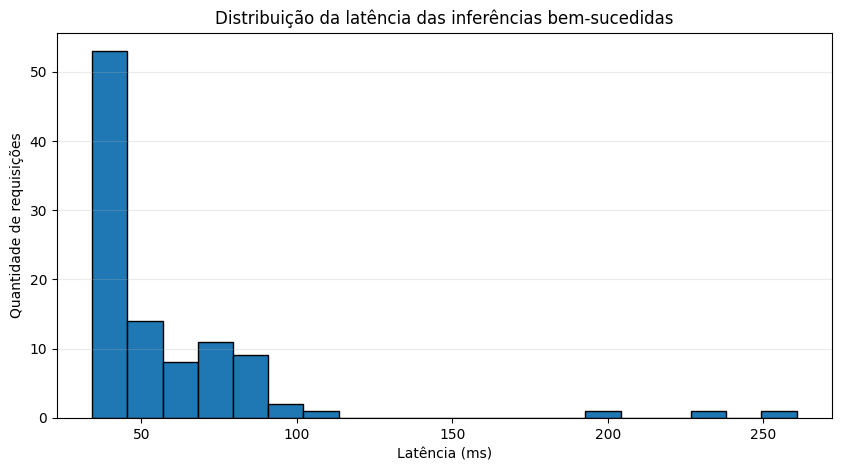

In [6]:
if not successful.empty:
    plt.figure(figsize=(10, 5))
    plt.hist(successful["latency_ms"], bins=20, edgecolor="black")
    plt.title("Distribuição da latência das inferências bem-sucedidas")
    plt.xlabel("Latência (ms)")
    plt.ylabel("Quantidade de requisições")
    plt.grid(axis="y", alpha=0.25)
    plt.show()

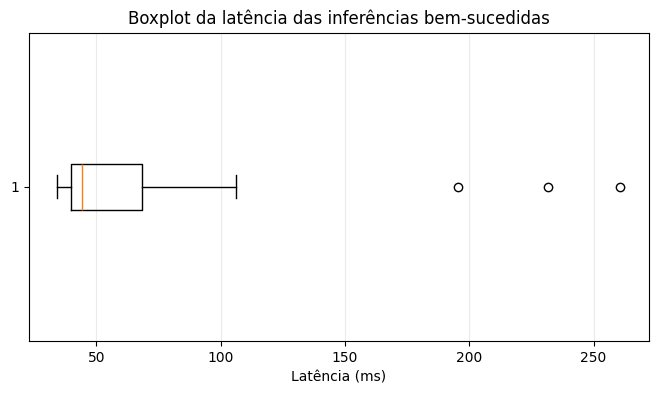

In [7]:
if not successful.empty:
    plt.figure(figsize=(8, 4))
    plt.boxplot(successful["latency_ms"], vert=False)
    plt.title("Boxplot da latência das inferências bem-sucedidas")
    plt.xlabel("Latência (ms)")
    plt.grid(axis="x", alpha=0.25)
    plt.show()

**Como interpretar:**
- No histograma, observe onde está concentrada a maior parte das requisições e se existe uma cauda de latências elevadas.
- No boxplot, a linha central representa a mediana; a caixa representa o intervalo entre o primeiro e o terceiro quartis (IQR).
- Pontos além dos limites dos bigodes podem indicar valores atípicos. Eles merecem investigação, mas não significam necessariamente falhas.

## 3. Distribuição da confiança das detecções

,confidence
count,101.000000
mean,0.655782
std,0.081028
min,0.172041
25%,0.654756
50%,0.671828
75%,0.687689
max,0.724306


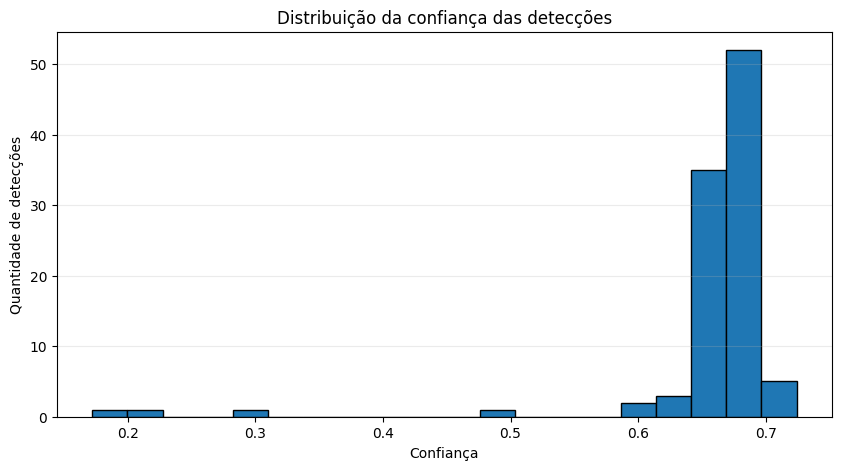

In [8]:
# A confiança existe quando output é um objeto e a inferência retornou uma detecção.
confidence = pd.to_numeric(
    df.get("output_confidence", pd.Series(index=df.index, dtype="float64")),
    errors="coerce"
).dropna()

if confidence.empty:
    print("Não há valores de confiança disponíveis nos logs.")
else:
    display(confidence.describe().to_frame("confidence"))

    plt.figure(figsize=(10, 5))
    plt.hist(confidence, bins=20, edgecolor="black")
    plt.title("Distribuição da confiança das detecções")
    plt.xlabel("Confiança")
    plt.ylabel("Quantidade de detecções")
    plt.grid(axis="y", alpha=0.25)
    plt.show()

## 4. Estatísticas das imagens de entrada

,input_pixel_mean,input_pixel_std
count,101.000000,101.000000
mean,135.173132,59.215425
std,26.199605,12.264560
min,25.125559,15.121355
25%,129.836105,53.523126
50%,134.587703,63.160597
75%,149.717917,64.565429
max,192.226308,89.599591


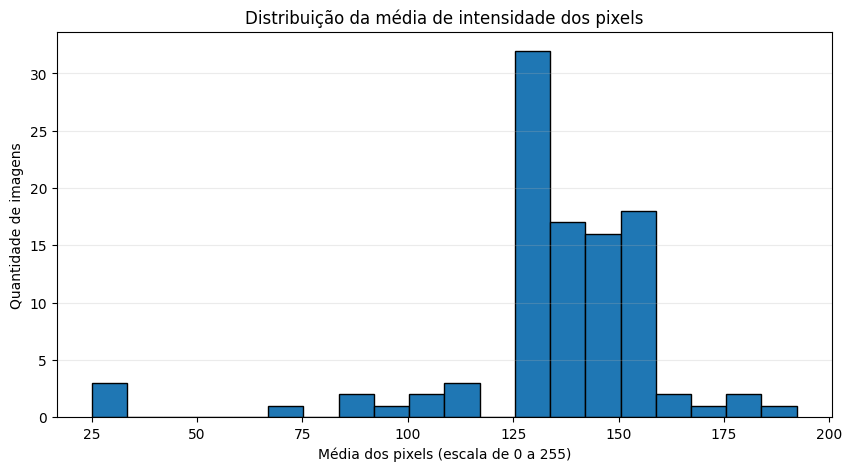

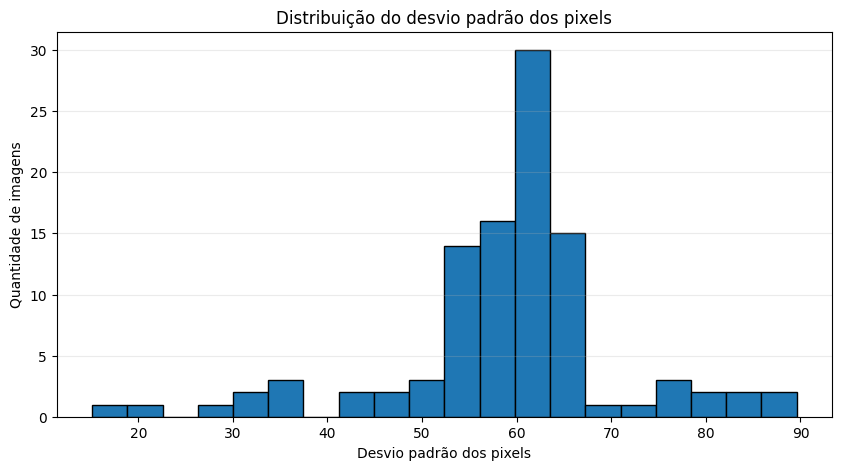

In [9]:
# Registros de erro do middleware não possuem pixel_mean/pixel_std.
pixel_columns = ["input_pixel_mean", "input_pixel_std"]
available_pixel_columns = [col for col in pixel_columns if col in df.columns]

for col in available_pixel_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

pixel_data = df[available_pixel_columns].dropna(how="all")

if pixel_data.empty:
    print("Não há estatísticas de pixels disponíveis nos logs.")
else:
    display(pixel_data.describe())

    if "input_pixel_mean" in pixel_data:
        plt.figure(figsize=(10, 5))
        plt.hist(pixel_data["input_pixel_mean"].dropna(), bins=20, edgecolor="black")
        plt.title("Distribuição da média de intensidade dos pixels")
        plt.xlabel("Média dos pixels (escala de 0 a 255)")
        plt.ylabel("Quantidade de imagens")
        plt.grid(axis="y", alpha=0.25)
        plt.show()

    if "input_pixel_std" in pixel_data:
        plt.figure(figsize=(10, 5))
        plt.hist(pixel_data["input_pixel_std"].dropna(), bins=20, edgecolor="black")
        plt.title("Distribuição do desvio padrão dos pixels")
        plt.xlabel("Desvio padrão dos pixels")
        plt.ylabel("Quantidade de imagens")
        plt.grid(axis="y", alpha=0.25)
        plt.show()

## 5. Evolução temporal das requisições

Este gráfico ajuda a observar mudanças ao longo do tempo. Ele agrega as requisições por intervalo de tempo; ajuste `freq` para `"h"` (hora), `"D"` (dia) ou `"min"` (minuto), conforme o volume de dados.

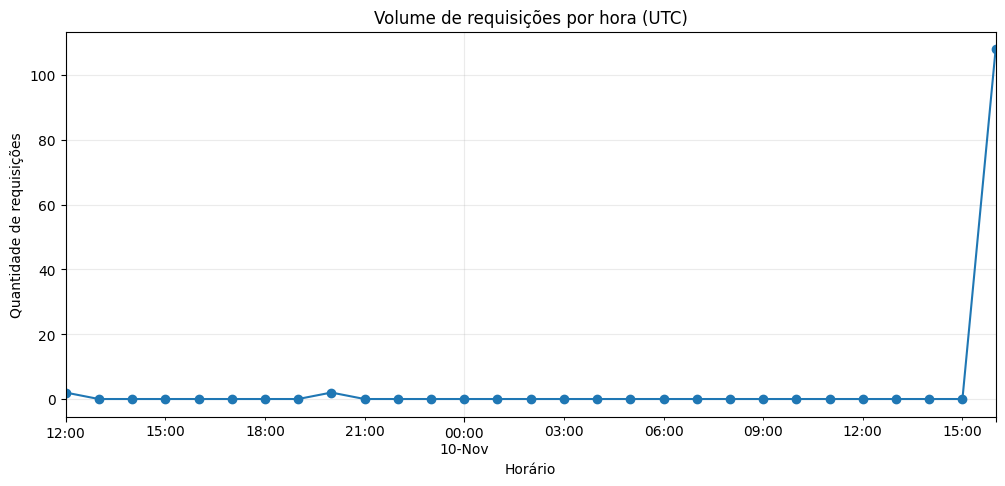

In [10]:
temporal = df.dropna(subset=["timestamp"]).copy()

if temporal.empty:
    print("Não há timestamps válidos.")
else:
    temporal = temporal.set_index("timestamp")
    requests_per_hour = temporal.resample("h").size()

    plt.figure(figsize=(12, 5))
    requests_per_hour.plot(kind="line", marker="o")
    plt.title("Volume de requisições por hora (UTC)")
    plt.xlabel("Horário")
    plt.ylabel("Quantidade de requisições")
    plt.grid(alpha=0.25)
    plt.show()

## 6. Resumo dos erros

Os erros são apresentados separadamente para facilitar a inspeção. No caso dos registros capturados pelo middleware, a latência representa o tempo observado na camada ASGI, não necessariamente o mesmo intervalo medido dentro do método `predict`.

In [11]:
error_df = df[df["status_code"].ge(400)].copy()

if error_df.empty:
    print("Nenhum erro registrado.")
else:
    error_summary = (
        error_df.groupby(["status_code", "error"], dropna=False)
        .size()
        .reset_index(name="quantidade")
        .sort_values("quantidade", ascending=False)
    )
    display(error_summary)

    display(
        error_df[["timestamp", "request_id", "status_code", "latency_ms", "error"]]
        .sort_values("timestamp", ascending=False)
        .head(20)
    )

,status_code,error,quantidade
0,500,HTTP 500 returned by BentoML,11


,timestamp,request_id,status_code,latency_ms,error
111,2026-11-10 16:31:01.878549+00:00,01082bf7-8dfb-40c9-877c-b4883c599f1b,500,4.5548,HTTP 500 returned by BentoML
110,2026-11-10 16:30:59.825440+00:00,090f1360-7749-4f9b-b926-72bbc82a6fe7,500,2.2476,HTTP 500 returned by BentoML
109,2026-11-10 16:30:57.755136+00:00,b855152f-2aec-41c6-9513-ceb4f9c5c41d,500,1.9956,HTTP 500 returned by BentoML
108,2026-11-10 16:30:55.647630+00:00,428b8782-fba9-4f8a-880c-51debedaaee2,500,1.9692,HTTP 500 returned by BentoML
107,2026-11-10 16:30:53.605537+00:00,7a4a3150-8e6f-4c1b-bd32-3f9ea908a4b4,500,5.2111,HTTP 500 returned by BentoML
106,2026-11-10 16:30:51.523911+00:00,30261118-a2e7-418f-9f2a-d0ae68fd5794,500,5.1303,HTTP 500 returned by BentoML
105,2026-11-10 16:30:49.449195+00:00,5f73d53d-f1a6-4d75-9e02-485f7fb71061,500,7.4778,HTTP 500 returned by BentoML
104,2026-11-10 16:30:47.381580+00:00,a7b7c5f8-eac4-4c62-8a11-c0b91105d444,500,2.1872,HTTP 500 returned by BentoML
103,2026-11-10 16:30:45.318463+00:00,ed7f6f63-93db-4147-9f0a-cff86ae591a3,500,4.8606,HTTP 500 returned by BentoML
102,2026-11-10 16:30:43.270884+00:00,384e8747-5143-4a49-ac38-46bf6faabdae,500,250.4468,HTTP 500 returned by BentoML


## 7. Exportar uma tabela tratada

Opcionalmente, exporte os registros normalizados para CSV. O JSONL original permanece intacto.

In [ ]:
EXPORT_PATH = Path("../logs/inference_analysis.csv")
df.to_csv(EXPORT_PATH, index=False, encoding="utf-8-sig")
print(f"Arquivo exportado: {EXPORT_PATH.resolve()}")

Arquivo exportado: C:\Users\Felip\OneDrive\Documentos\Faculdade\MLOps\voltlensAI\logs\inference_analysis.csv
